# Goodbooks-10k: Improved Exploratory Data Analysis

Explore explicit ratings and assess recommender choices. Individual, larger visualizations for clearer analysis.
Run all cells with pandas, NumPy, matplotlib and IPython installed.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import lenskit

SEED = 42
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p/'data'/'ratings.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Run from the repository root or its notebooks directory.')
DATA = ROOT/'data'

ratings_raw = pd.read_csv(DATA/'ratings.csv')
books = pd.read_csv(DATA/'books.csv')
book_tags = pd.read_csv(DATA/'book_tags.csv')
tags = pd.read_csv(DATA/'tags.csv')

print('Dataset loaded successfully')
display(pd.DataFrame({'rows':[len(ratings_raw),len(books),len(book_tags),len(tags)]}, 
                     index=['ratings','books','book_tags','tags']))

Dataset loaded successfully


,rows
ratings,5976479
books,10000
book_tags,999912
tags,34252


## 1. Data Quality Assessment

In [2]:
valid = ratings_raw[['user_id','book_id','rating']].notna().all(axis=1) & ratings_raw.rating.isin([1,2,3,4,5])
conflicts = ratings_raw.groupby(['user_id','book_id']).rating.nunique().gt(1)

display(pd.Series({
    'invalid_rows':int((~valid).sum()),
    'exact_duplicates':int(ratings_raw.duplicated().sum()),
    'repeated_user_book_rows':int(ratings_raw.duplicated(['user_id','book_id']).sum()),
    'conflicting_pairs':int(conflicts.sum()),
    'unknown_books':int((~ratings_raw.book_id.isin(books.book_id)).sum()),
    'duplicate_metadata_ids':int(books.book_id.duplicated().sum())
}).to_frame('count'))

assert books.book_id.is_unique
assert not conflicts.any(), 'Resolve conflicting ratings explicitly; timestamps are unavailable.'

ratings = ratings_raw.loc[valid].drop_duplicates(['user_id','book_id']).copy()
assert ratings.book_id.isin(books.book_id).all()
print(f'\nRetained {len(ratings):,} of {len(ratings_raw):,} ratings (100% valid)')

,count
invalid_rows,0
exact_duplicates,0
repeated_user_book_rows,0
conflicting_pairs,0
unknown_books,0
duplicate_metadata_ids,0



Retained 5,976,479 of 5,976,479 ratings (100% valid)


### Missing Values in Books Metadata

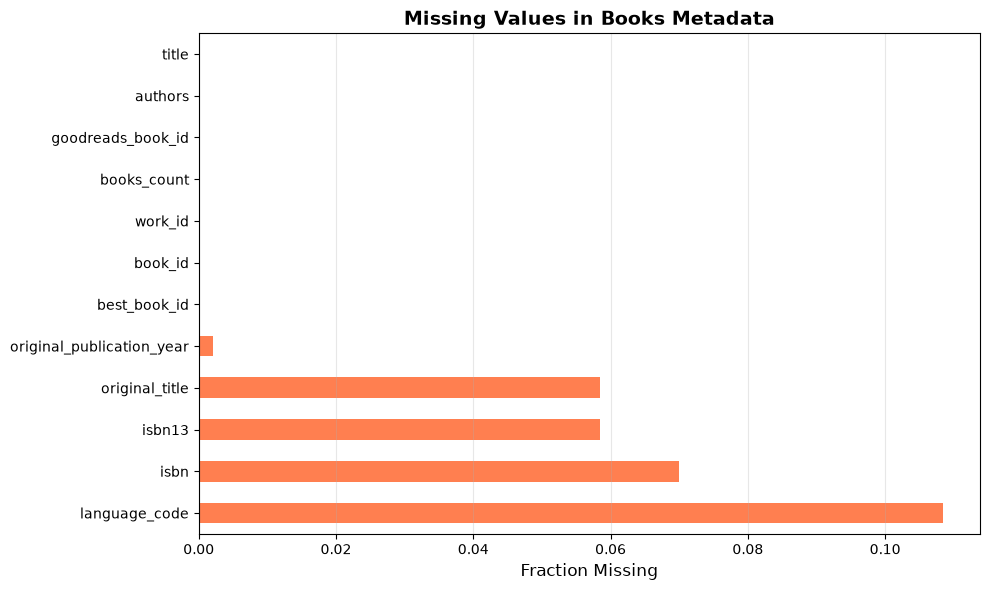

,missing_fraction
language_code,0.1084
isbn,0.0700
isbn13,0.0585
original_title,0.0585
original_publication_year,0.0021
best_book_id,0.0000
book_id,0.0000
work_id,0.0000
books_count,0.0000
goodreads_book_id,0.0000


In [3]:
fig, ax = plt.subplots(figsize=(10, 6))
missing_data = books.isna().mean().sort_values(ascending=False).head(12)
missing_data.plot(kind='barh', ax=ax, color='coral')
ax.set_xlabel('Fraction Missing', fontsize=12)
ax.set_title('Missing Values in Books Metadata', fontsize=14, fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

display(missing_data.to_frame('missing_fraction'))

## 2. User and Item Statistics

In [4]:
user_counts = ratings.groupby('user_id').size()
item_counts = ratings.groupby('book_id').size()
n_users, n_items = len(user_counts), len(item_counts)
density = len(ratings)/(n_users*n_items)

display(pd.Series({
    'users': n_users,
    'rated_books': n_items,
    'total_ratings': len(ratings),
    'density': f'{density:.4f}',
    'sparsity': f'{1-density:.4f}',
    'mean_rating': f'{ratings.rating.mean():.2f}'
}).to_frame('value'))

print('\nRatings per user:')
display(user_counts.describe(percentiles=[.1,.25,.5,.75,.9,.99]))
print('\nRatings per book:')
display(item_counts.describe(percentiles=[.1,.25,.5,.75,.9,.99]))

,value
users,53424
rated_books,10000
total_ratings,5976479
density,0.0112
sparsity,0.9888
mean_rating,3.92



Ratings per user:


count    53424.000000
mean       111.868804
std         26.071224
min         19.000000
10%         82.000000
25%         96.000000
50%        111.000000
75%        128.000000
90%        146.000000
99%        176.000000
max        200.000000
dtype: float64


Ratings per book:


count    10000.000000
mean       597.647900
std       1267.289788
min          8.000000
10%        115.000000
25%        155.000000
50%        248.000000
75%        503.000000
90%       1180.300000
99%       6305.020000
max      22806.000000
dtype: float64

### Rating Distribution

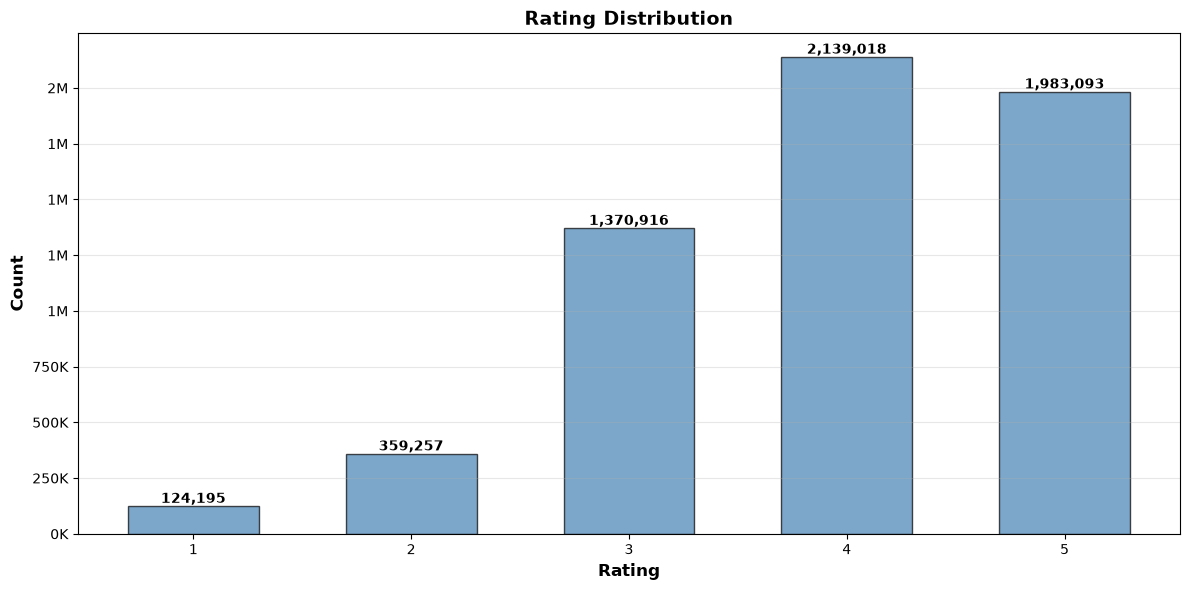

In [5]:
fig, ax = plt.subplots(figsize=(12, 6))
rating_counts = ratings.rating.value_counts().sort_index()
bars = ax.bar(rating_counts.index, rating_counts.values, color='steelblue', edgecolor='black', alpha=0.7, width=0.6)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{int(height):,}',
            ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_xlabel('Rating', fontsize=12, fontweight='bold')
ax.set_ylabel('Count', fontsize=12, fontweight='bold')
ax.set_title('Rating Distribution', fontsize=14, fontweight='bold')
ax.set_xticks([1, 2, 3, 4, 5])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1e6)}M' if x >= 1e6 else f'{int(x/1e3)}K'))
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### User Activity Distribution

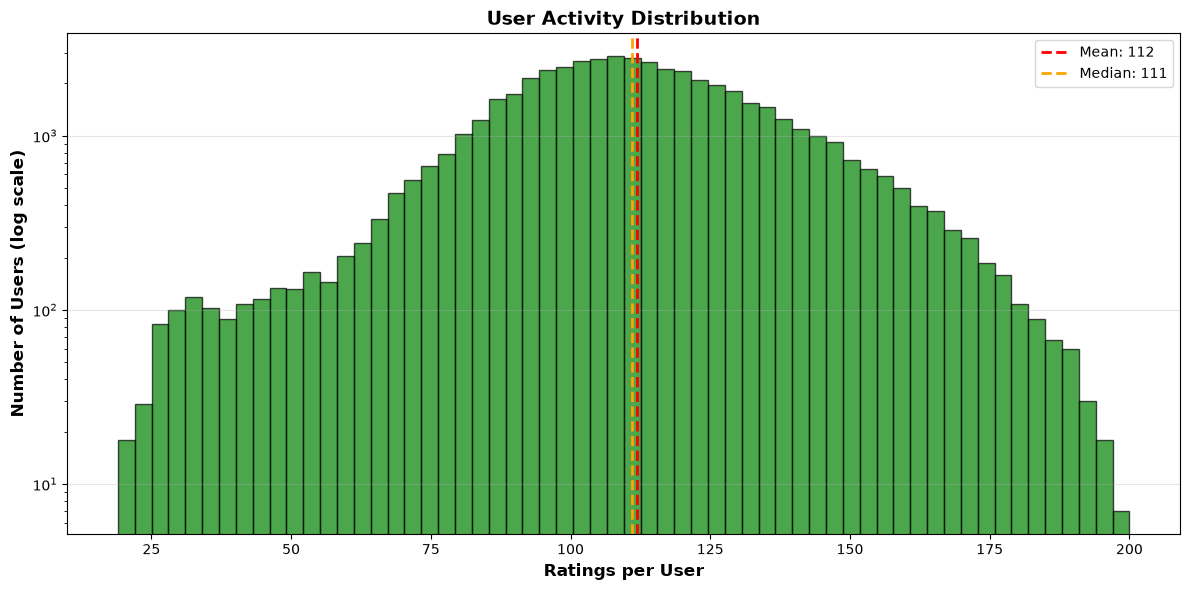

In [6]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(user_counts, bins=60, color='green', alpha=0.7, edgecolor='black')
ax.set_yscale('log')
ax.set_xlabel('Ratings per User', fontsize=12, fontweight='bold')
ax.set_ylabel('Number of Users (log scale)', fontsize=12, fontweight='bold')
ax.set_title('User Activity Distribution', fontsize=14, fontweight='bold')
ax.axvline(user_counts.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {user_counts.mean():.0f}')
ax.axvline(user_counts.median(), color='orange', linestyle='--', linewidth=2, label=f'Median: {user_counts.median():.0f}')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Book Popularity Distribution

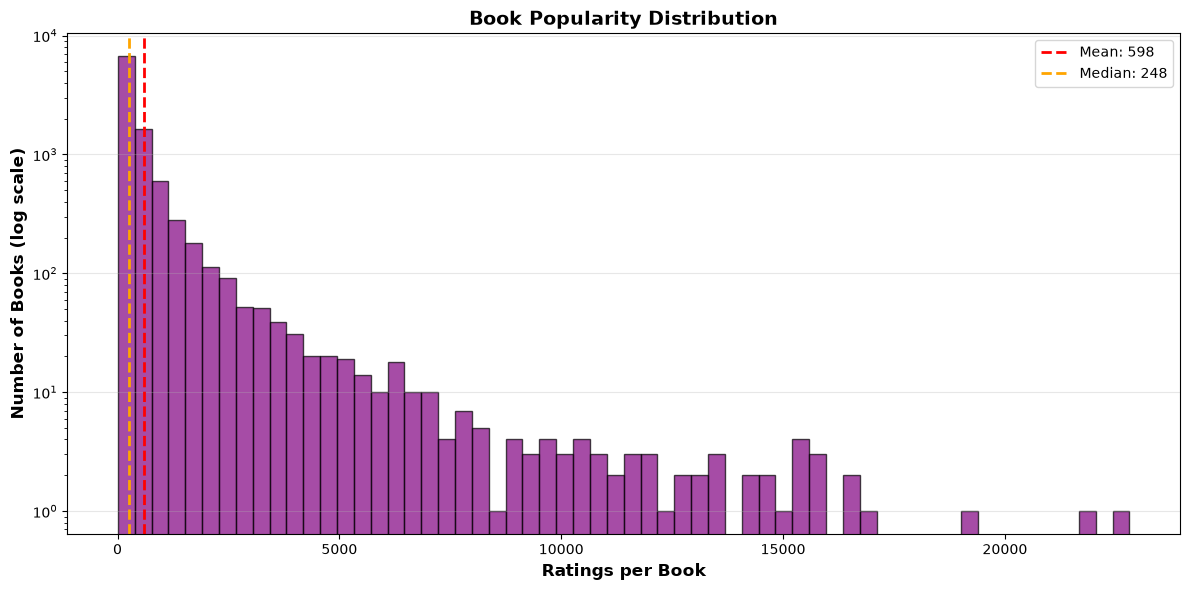

In [7]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(item_counts, bins=60, color='purple', alpha=0.7, edgecolor='black')
ax.set_yscale('log')
ax.set_xlabel('Ratings per Book', fontsize=12, fontweight='bold')
ax.set_ylabel('Number of Books (log scale)', fontsize=12, fontweight='bold')
ax.set_title('Book Popularity Distribution', fontsize=14, fontweight='bold')
ax.axvline(item_counts.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {item_counts.mean():.0f}')
ax.axvline(item_counts.median(), color='orange', linestyle='--', linewidth=2, label=f'Median: {item_counts.median():.0f}')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Sparsity and Popularity Bias

### Popularity Concentration (Pareto Distribution)

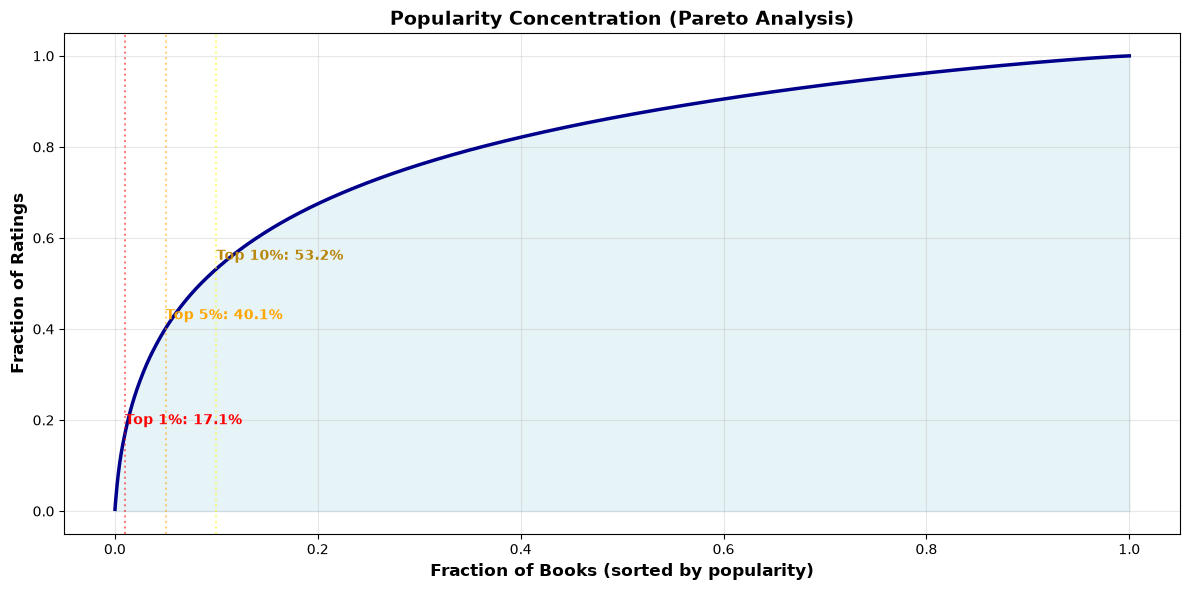

Top 1% of books (100 books) receive 17.1% of ratings
Top 5% of books (500 books) receive 40.1% of ratings
Top 10% of books (1000 books) receive 53.2% of ratings


In [8]:
ranked = item_counts.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(1, n_items+1) / n_items
y = ranked.cumsum() / len(ratings)

ax.plot(x, y, linewidth=2.5, color='darkblue')
ax.fill_between(x, 0, y, alpha=0.3, color='lightblue')

ax.set_xlabel('Fraction of Books (sorted by popularity)', fontsize=12, fontweight='bold')
ax.set_ylabel('Fraction of Ratings', fontsize=12, fontweight='bold')
ax.set_title('Popularity Concentration (Pareto Analysis)', fontsize=14, fontweight='bold')

top_1_pct = max(1, int(np.ceil(.01*n_items)))
top_5_pct = max(1, int(np.ceil(.05*n_items)))
top_10_pct = max(1, int(np.ceil(.1*n_items)))

pct_1 = ranked.head(top_1_pct).sum()/len(ratings)
pct_5 = ranked.head(top_5_pct).sum()/len(ratings)
pct_10 = ranked.head(top_10_pct).sum()/len(ratings)

ax.axvline(0.01, color='red', linestyle=':', alpha=0.5)
ax.axvline(0.05, color='orange', linestyle=':', alpha=0.5)
ax.axvline(0.1, color='yellow', linestyle=':', alpha=0.5)

ax.text(0.01, pct_1 + 0.02, f'Top 1%: {pct_1:.1%}', fontsize=10, fontweight='bold', color='red')
ax.text(0.05, pct_5 + 0.02, f'Top 5%: {pct_5:.1%}', fontsize=10, fontweight='bold', color='orange')
ax.text(0.1, pct_10 + 0.02, f'Top 10%: {pct_10:.1%}', fontsize=10, fontweight='bold', color='darkgoldenrod')

ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Top 1% of books ({top_1_pct} books) receive {pct_1:.1%} of ratings')
print(f'Top 5% of books ({top_5_pct} books) receive {pct_5:.1%} of ratings')
print(f'Top 10% of books ({top_10_pct} books) receive {pct_10:.1%} of ratings')

### Top 20 Most Rated Books

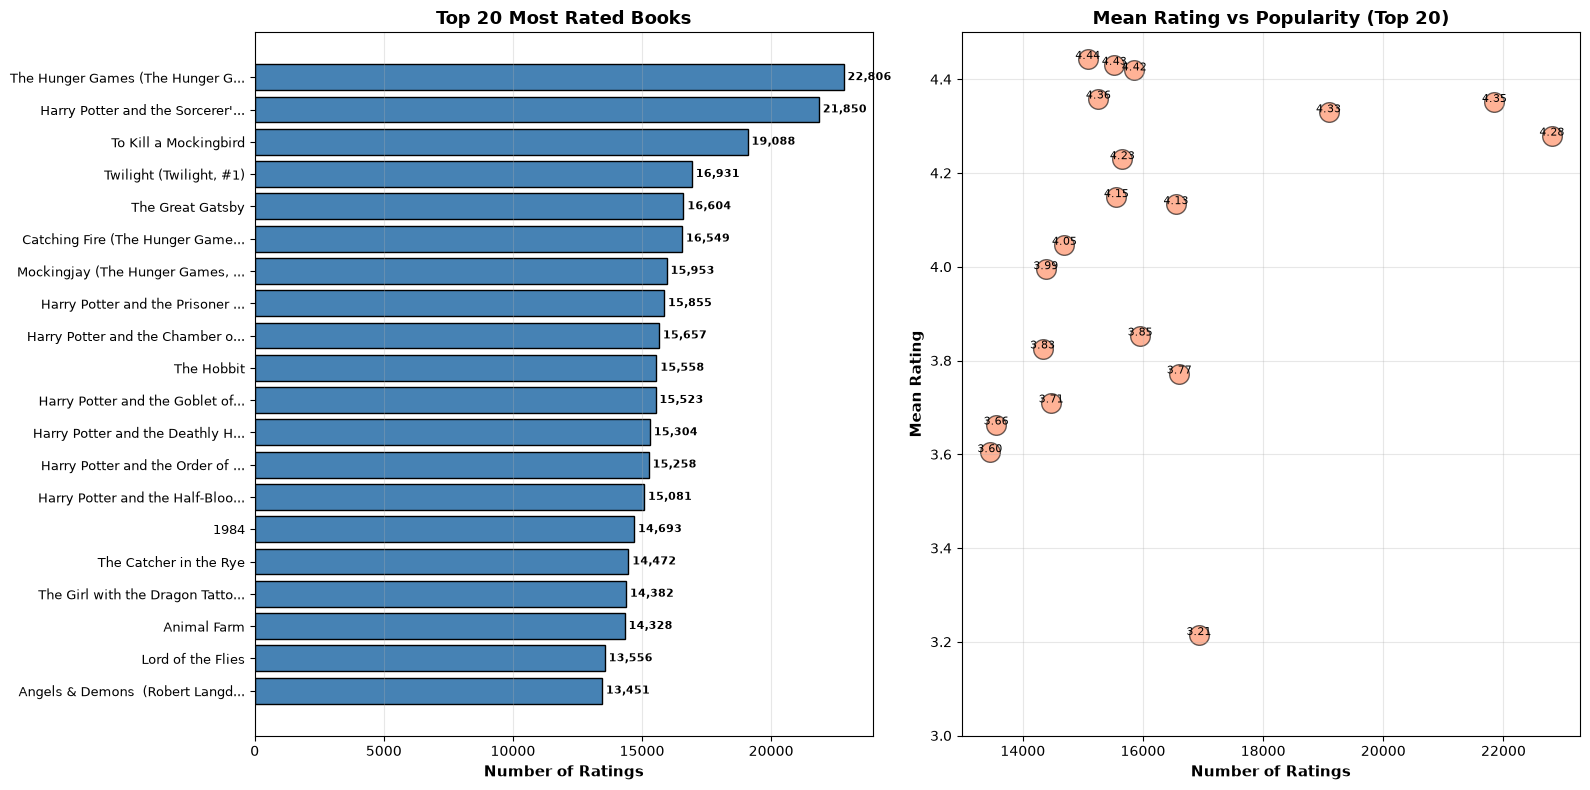

,sample_count,sample_mean,title,authors
book_id,,,,
1,22806,4.279707,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins
2,21850,4.351350,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré"
4,19088,4.329369,To Kill a Mockingbird,Harper Lee
3,16931,3.214341,"Twilight (Twilight, #1)",Stephenie Meyer
5,16604,3.772224,The Great Gatsby,F. Scott Fitzgerald
17,16549,4.133422,"Catching Fire (The Hunger Games, #2)",Suzanne Collins
20,15953,3.853131,"Mockingjay (The Hunger Games, #3)",Suzanne Collins
18,15855,4.418732,Harry Potter and the Prisoner of Azkaban (Harr...,"J.K. Rowling, Mary GrandPré, Rufus Beck"
23,15657,4.229418,Harry Potter and the Chamber of Secrets (Harry...,"J.K. Rowling, Mary GrandPré"


In [9]:
summary = ratings.groupby('book_id').rating.agg(sample_count='size', sample_mean='mean')
top_books = (summary.join(books.set_index('book_id')[['title','authors']])
             .sort_values('sample_count',ascending=False).head(20))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

ax1.barh(range(len(top_books)), top_books['sample_count'], color='steelblue', edgecolor='black')
ax1.set_yticks(range(len(top_books)))
ax1.set_yticklabels([f"{t[:30]}..." if len(t) > 30 else t for t in top_books['title']], fontsize=9)
ax1.set_xlabel('Number of Ratings', fontsize=11, fontweight='bold')
ax1.set_title('Top 20 Most Rated Books', fontsize=13, fontweight='bold')
ax1.invert_yaxis()
ax1.grid(axis='x', alpha=0.3)

for i, v in enumerate(top_books['sample_count']):
    ax1.text(v, i, f' {int(v):,}', va='center', fontsize=8, fontweight='bold')

ax2.scatter(top_books['sample_count'], top_books['sample_mean'], s=200, alpha=0.6, color='coral', edgecolor='black')
ax2.set_xlabel('Number of Ratings', fontsize=11, fontweight='bold')
ax2.set_ylabel('Mean Rating', fontsize=11, fontweight='bold')
ax2.set_title('Mean Rating vs Popularity (Top 20)', fontsize=13, fontweight='bold')
ax2.grid(alpha=0.3)
ax2.set_ylim(3, 4.5)

for idx, (count, mean_rating) in enumerate(zip(top_books['sample_count'], top_books['sample_mean'])):
    ax2.annotate(f"{mean_rating:.2f}", (count, mean_rating), fontsize=8, ha='center')

plt.tight_layout()
plt.show()

display(top_books[['sample_count', 'sample_mean', 'title', 'authors']])

### User Rating Generosity (Bias)

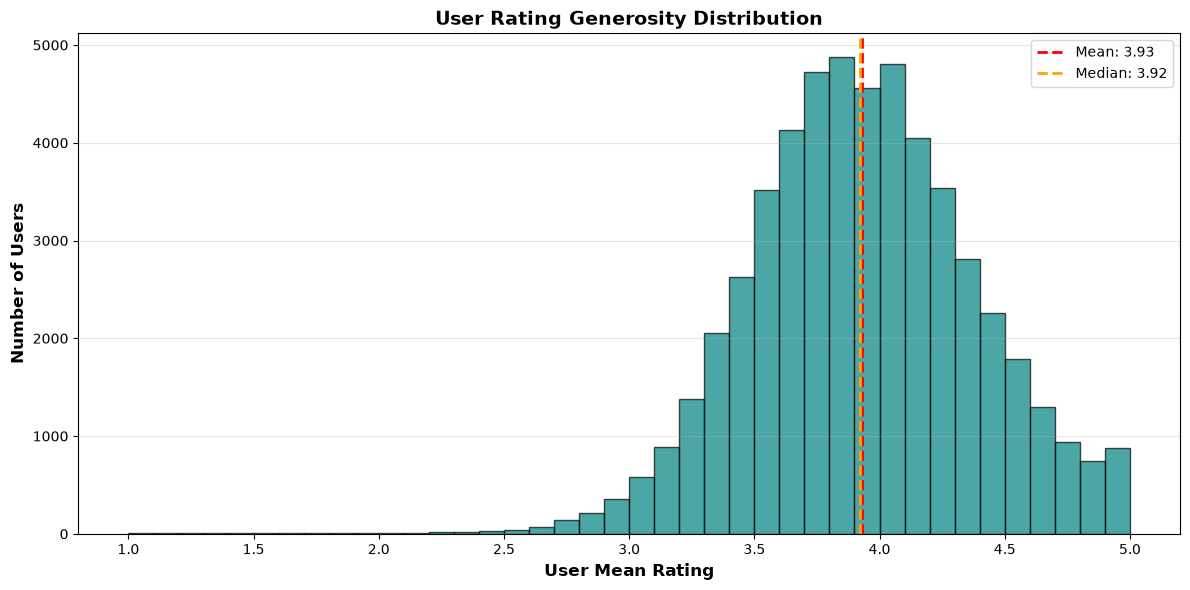

User mean rating range: 1.00 to 5.00
User rating std: mean=0.86, median=0.86


In [10]:
user_mean_ratings = ratings.groupby('user_id').rating.mean()
user_rating_std = ratings.groupby('user_id').rating.std()

fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(user_mean_ratings, bins=40, color='teal', alpha=0.7, edgecolor='black')
ax.axvline(user_mean_ratings.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {user_mean_ratings.mean():.2f}')
ax.axvline(user_mean_ratings.median(), color='orange', linestyle='--', linewidth=2, label=f'Median: {user_mean_ratings.median():.2f}')
ax.set_xlabel('User Mean Rating', fontsize=12, fontweight='bold')
ax.set_ylabel('Number of Users', fontsize=12, fontweight='bold')
ax.set_title('User Rating Generosity Distribution', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print(f'User mean rating range: {user_mean_ratings.min():.2f} to {user_mean_ratings.max():.2f}')
print(f'User rating std: mean={user_rating_std.mean():.2f}, median={user_rating_std.median():.2f}')

## 4. Content Coverage

In [11]:
tag_metadata = (book_tags.merge(tags, on='tag_id', how='left', validate='many_to_one')
                .merge(books[['book_id','goodreads_book_id']], on='goodreads_book_id', how='left', validate='many_to_one'))

display(pd.Series({
    'books_with_authors_fraction': books.authors.fillna('').str.strip().ne('').mean(),
    'books_with_titles_fraction': books.title.fillna('').str.strip().ne('').mean(),
    'books_with_tags_fraction': books.book_id.isin(tag_metadata.book_id.dropna()).mean(),
    'unmapped_tag_rows': tag_metadata.book_id.isna().sum(),
    'missing_tag_names': tag_metadata.tag_name.isna().sum()
}).to_frame('value'))

,value
books_with_authors_fraction,1.0
books_with_titles_fraction,1.0
books_with_tags_fraction,1.0
unmapped_tag_rows,0.0
missing_tag_names,0.0


### Top 25 Tags

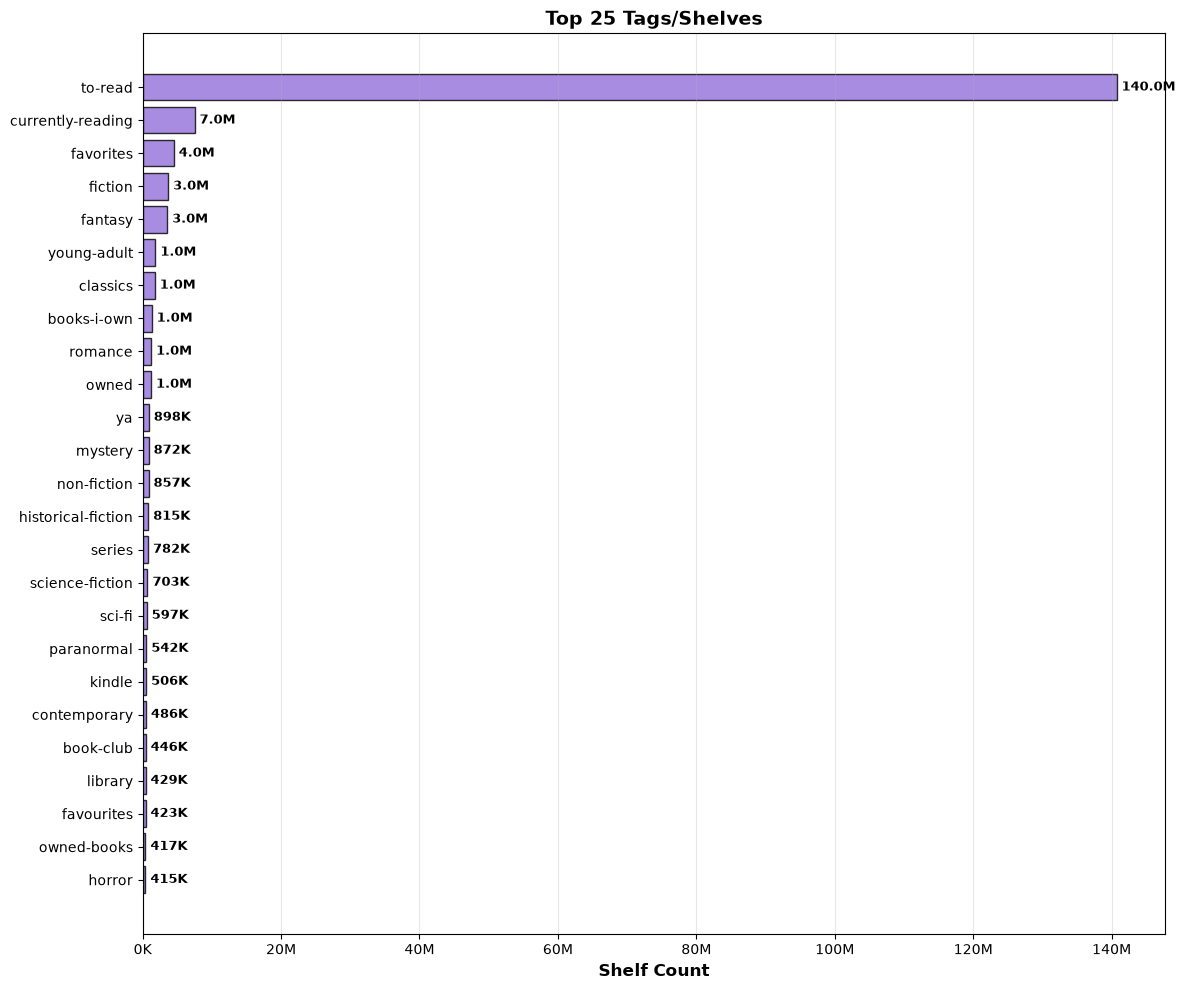

In [12]:
fig, ax = plt.subplots(figsize=(12, 10))
top_tags = tag_metadata.groupby('tag_name')['count'].sum().sort_values(ascending=False).head(25)

bars = ax.barh(range(len(top_tags)), top_tags.values, color='mediumpurple', edgecolor='black', alpha=0.8)
ax.set_yticks(range(len(top_tags)))
ax.set_yticklabels(top_tags.index, fontsize=10)
ax.set_xlabel('Shelf Count', fontsize=12, fontweight='bold')
ax.set_title('Top 25 Tags/Shelves', fontsize=14, fontweight='bold')
ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1e6)}M' if x >= 1e6 else f'{int(x/1e3)}K'))
ax.grid(axis='x', alpha=0.3)

for i, v in enumerate(top_tags.values):
    ax.text(v, i, f' {int(v/1e6):.1f}M' if v >= 1e6 else f' {int(v/1e3)}K', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

### Language Distribution

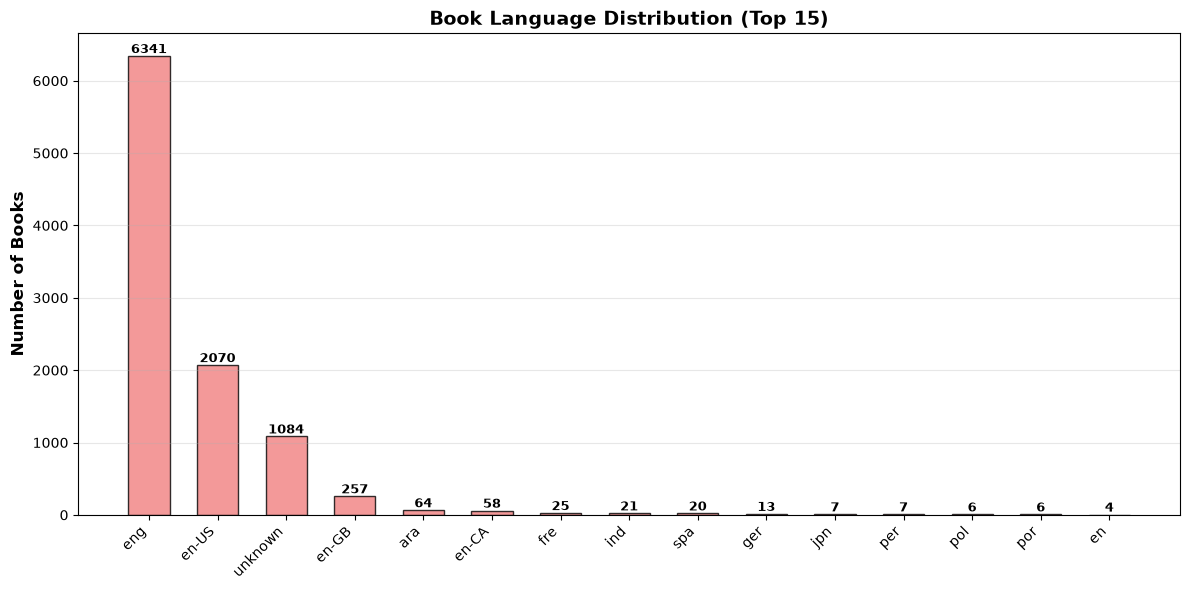

English books (eng + en-US + en-GB + en-CA): 8730 (87.3%)


In [13]:
fig, ax = plt.subplots(figsize=(12, 6))
lang_counts = books.language_code.fillna('unknown').value_counts().head(15)

bars = ax.bar(range(len(lang_counts)), lang_counts.values, color='lightcoral', edgecolor='black', alpha=0.8, width=0.6)
ax.set_xticks(range(len(lang_counts)))
ax.set_xticklabels(lang_counts.index, rotation=45, ha='right', fontsize=10)
ax.set_ylabel('Number of Books', fontsize=12, fontweight='bold')
ax.set_title('Book Language Distribution (Top 15)', fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{int(height)}',
            ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

print(f'English books (eng + en-US + en-GB + en-CA): {lang_counts[[k for k in lang_counts.index if "en" in str(k)]].sum()} ({lang_counts[[k for k in lang_counts.index if "en" in str(k)]].sum()/len(books):.1%})')

## 5. Group Feasibility Analysis

In [14]:
rng = np.random.default_rng(SEED)
histories = ratings.groupby('user_id').book_id.agg(set).to_dict()
users = np.array(sorted(histories))

rows = []
for size in [3, 4, 5]:
    for repeat in range(100):
        members = rng.choice(users, size=size, replace=False).tolist()
        sets = [histories[u] for u in members]
        overlap = [len(sets[a]&sets[b]) for a in range(size) for b in range(a+1,size)]
        rows.append({
            'size': size,
            'common_rated': len(set.intersection(*sets)),
            'mean_pair_overlap': np.mean(overlap),
            'unseen_by_everyone': n_items - len(set.union(*sets))
        })

group_stats = pd.DataFrame(rows).groupby('size').agg(
    median_common=('common_rated', 'median'),
    fraction_no_common=('common_rated', lambda x: x.eq(0).mean()),
    mean_pair_overlap=('mean_pair_overlap', 'mean'),
    median_candidates=('unseen_by_everyone', 'median')
)

display(group_stats)

,median_common,fraction_no_common,mean_pair_overlap,median_candidates
size,,,,
3,0.0,0.60,6.943333,9684.0
4,0.0,0.88,6.560000,9595.0
5,0.0,0.94,7.032000,9506.0


### Group Overlap Analysis

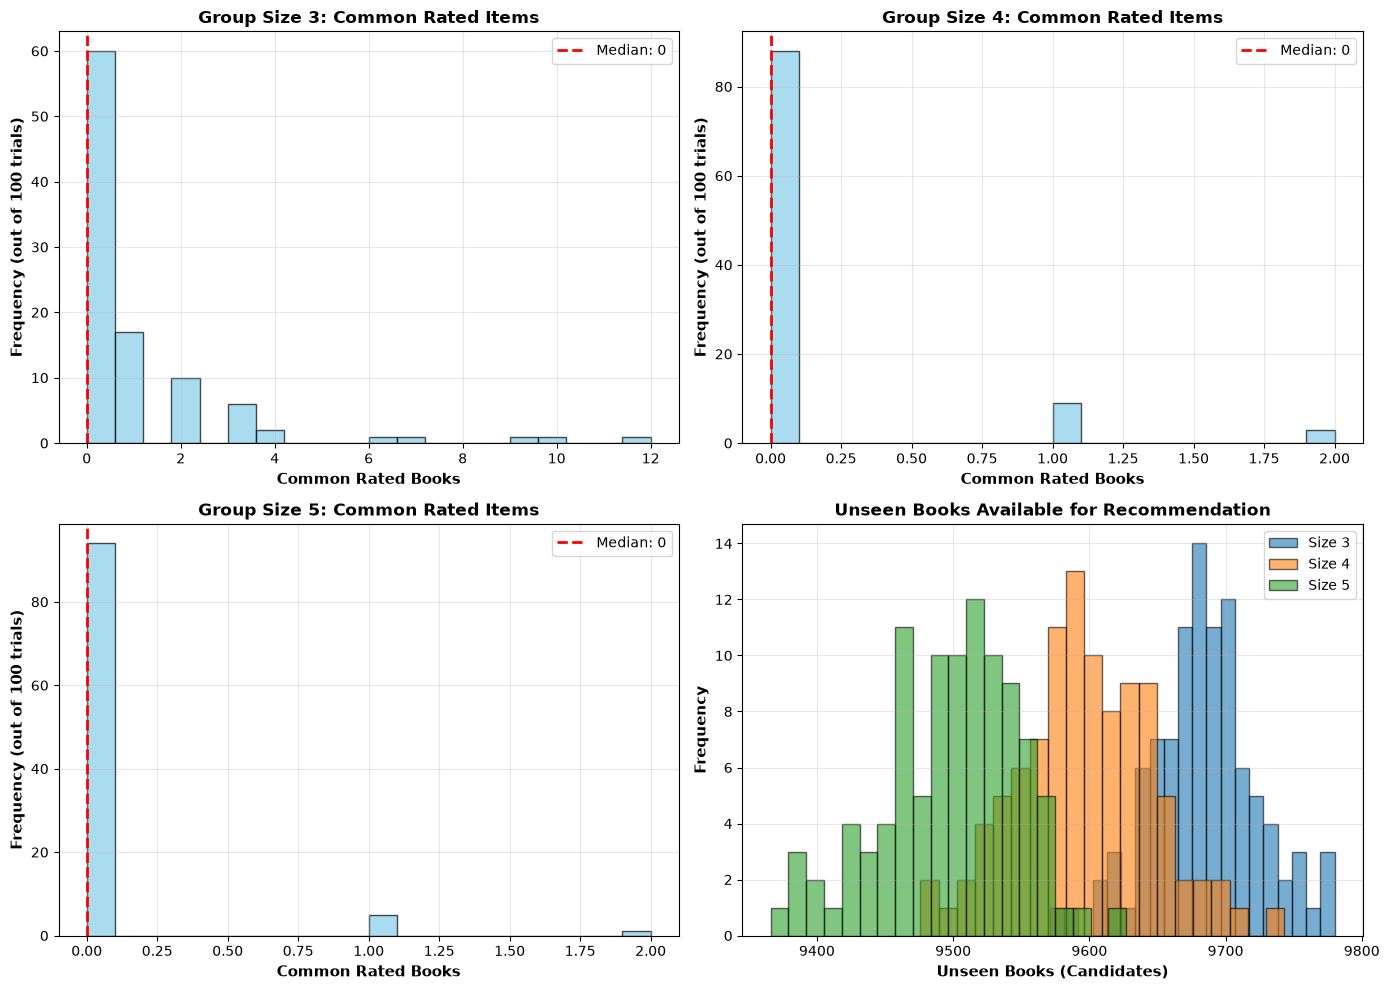

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Common rated items
pd.DataFrame(rows).groupby('size')['common_rated'].apply(list).apply(lambda x: x).to_list()
for i, size in enumerate([3, 4, 5]):
    ax = axes[i//2, i%2]
    data = [r['common_rated'] for r in rows if r['size'] == size]
    ax.hist(data, bins=20, color='skyblue', edgecolor='black', alpha=0.7)
    ax.axvline(np.median(data), color='red', linestyle='--', linewidth=2, label=f'Median: {np.median(data):.0f}')
    ax.set_xlabel('Common Rated Books', fontsize=11, fontweight='bold')
    ax.set_ylabel('Frequency (out of 100 trials)', fontsize=11, fontweight='bold')
    ax.set_title(f'Group Size {size}: Common Rated Items', fontsize=12, fontweight='bold')
    ax.legend()
    ax.grid(alpha=0.3)

# Unseen by everyone
data = [r['unseen_by_everyone'] for r in rows if r['size'] == 3]
ax = axes[1, 1]
ax.hist([r['unseen_by_everyone'] for r in rows if r['size'] == 3], bins=20, label='Size 3', alpha=0.6, edgecolor='black')
ax.hist([r['unseen_by_everyone'] for r in rows if r['size'] == 4], bins=20, label='Size 4', alpha=0.6, edgecolor='black')
ax.hist([r['unseen_by_everyone'] for r in rows if r['size'] == 5], bins=20, label='Size 5', alpha=0.6, edgecolor='black')
ax.set_xlabel('Unseen Books (Candidates)', fontsize=11, fontweight='bold')
ax.set_ylabel('Frequency', fontsize=11, fontweight='bold')
ax.set_title('Unseen Books Available for Recommendation', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Memory Requirements for Similarity Models

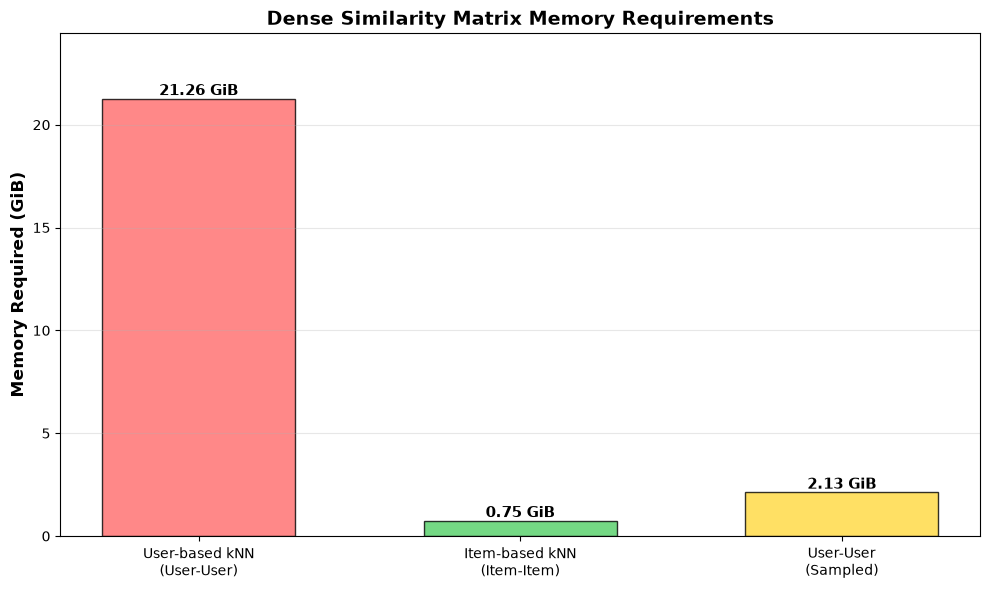

,Memory (GiB)
Model,
User-based kNN\n(User-User),21.264879
Item-based kNN\n(Item-Item),0.745058
User-User\n(Sampled),2.126488


In [16]:
fig, ax = plt.subplots(figsize=(10, 6))

memory_data = pd.DataFrame({
    'Model': ['User-based kNN\n(User-User)', 'Item-based kNN\n(Item-Item)', 'User-User\n(Sampled)'],
    'Memory (GiB)': [
        n_users**2 * 8 / 2**30,
        n_items**2 * 8 / 2**30,
        (n_users**2 * 8 / 2**30) * 0.1  # Assuming 10% sampling
    ]
})

colors = ['#ff6b6b', '#51cf66', '#ffd93d']
bars = ax.bar(memory_data['Model'], memory_data['Memory (GiB)'], color=colors, edgecolor='black', alpha=0.8, width=0.6)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.2f} GiB',
            ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_ylabel('Memory Required (GiB)', fontsize=12, fontweight='bold')
ax.set_title('Dense Similarity Matrix Memory Requirements', fontsize=14, fontweight='bold')
ax.set_ylim(0, max(memory_data['Memory (GiB)']) * 1.15)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

display(memory_data.set_index('Model'))

In [12]:
#cold start analysis Books/users with <5 ratings: how many? What fraction of catalog?
data = pd.read_csv('C:\\Users\\EGE\\Documents\\GitHub\\RecSys-2026\\data\\ratings.csv')
data = data.rename(columns={'book_id': 'item_id'})
cold_start_user_threshold = 5
cold_start_item_threshold = 5
user_interaction_counts = data.groupby("user_id").size()
item_interaction_counts = data.groupby("item_id").size()
cold_start_users = user_interaction_counts[user_interaction_counts < cold_start_user_threshold]
cold_start_items = item_interaction_counts[item_interaction_counts < cold_start_item_threshold]

print(f"Number of cold start users: {len(cold_start_users)}")
print(f"Number of cold start items: {len(cold_start_items)}")
print(f"Percentage of cold start users: {len(cold_start_users) / len(user_interaction_counts) * 100:.2f}%")
print(f"Percentage of cold start items: {len(cold_start_items) / len(item_interaction_counts) * 100:.2f}%")



Number of cold start users: 0
Number of cold start items: 0
Percentage of cold start users: 0.00%
Percentage of cold start items: 0.00%


We found out upon further inspection that the goodbooks dataset was prefiltered with minimum rating per user being 19 and per book being 8

In [23]:
cold_start_user_threshold = 100  # min is 19
cold_start_item_threshold = 100  # min is 8

cold_start_users = user_interaction_counts[user_interaction_counts < cold_start_user_threshold]
cold_start_items = item_interaction_counts[item_interaction_counts < cold_start_item_threshold]

some_user_id = cold_start_users.sample(1).index[0]
some_item_id = cold_start_items.sample(1).index[0]

sim_cold_user = data[data.user_id == some_user_id]
sim_cold_item = data[data.item_id == some_item_id]

print(f"Sample cold start user ID: {some_user_id}")
print(f"Sample cold start user interactions ({len(sim_cold_user)}):\n{sim_cold_user}")
print(f"Sample cold start item ID: {some_item_id}")
print(f"Sample cold start item interactions ({len(sim_cold_item)}):\n{sim_cold_item}")
print(f"Sample cold start user interaction count: {len(sim_cold_user)}")
print(f"Sample cold start item interaction count: {len(sim_cold_item)}")
print(f"Total number of cold start users: {len(cold_start_users)}")
print(f"Total number of cold start items: {len(cold_start_items)}")
print(f"Percentage of cold start users: {len(cold_start_users) / len(user_interaction_counts) * 100:.2f}%")
print(f"Percentage of cold start items: {len(cold_start_items) / len(item_interaction_counts) * 100:.2f}%")



Sample cold start user ID: 22618
Sample cold start user interactions (87):
         user_id  item_id  rating
1592394    22618       16       5
1592401    22618       93       2
1592403    22618       42       2
1592404    22618      518       4
1592408    22618        2       5
...          ...      ...     ...
5011156    22618     5994       3
5011174    22618      300       5
5011175    22618       15       4
5350668    22618     1104       1
5731070    22618      279       4

[87 rows x 3 columns]
Sample cold start item ID: 9381
Sample cold start item interactions (98):
         user_id  item_id  rating
4405596    24988     9381       3
4428862    19778     9381       3
4441512    16707     9381       3
4461433    34516     9381       5
4469164     2293     9381       5
...          ...      ...     ...
5897739    11437     9381       4
5940967    50816     9381       5
5957286    12784     9381       4
5964377     9614     9381       4
5968134     5268     9381       4

[98 rows x 

In [26]:
MIN_RATINGS = 20  # below this, skew/kurtosis are unreliable — filter before ranking

item_stats = data.groupby("item_id")["rating"].agg(
    count="size", mean="mean", std="std",
    skew="skew",
    kurt=lambda s: s.kurt()  # pandas gives excess (Fisher) kurtosis, normal = 0
).query("count >= @MIN_RATINGS")

# Sarle's bimodality coefficient: BC > 0.555 (uniform dist. reference) suggests bimodal/multimodal shape
item_stats["bimodality_coef"] = (item_stats["skew"]**2 + 1) / (item_stats["kurt"] + 3)

# Extreme-rating fraction: how much of the mass sits at 1 or 5 vs the middle (3)
rating_frac = (data.groupby("item_id")["rating"]
               .value_counts(normalize=True).unstack(fill_value=0))
item_stats["frac_extreme"] = rating_frac.get(1, 0) + rating_frac.get(5, 0)
item_stats["frac_middle"] = rating_frac.get(3, 0)
item_stats["polarization_index"] = item_stats["frac_extreme"] - item_stats["frac_middle"]

print(f"Items analyzed (>= {MIN_RATINGS} ratings): {len(item_stats)} / {data.item_id.nunique()}")
print(f"Items flagged as bimodal (BC > 0.555): {(item_stats.bimodality_coef > 0.555).sum()} "
      f"({(item_stats.bimodality_coef > 0.555).mean()*100:.2f}%)")
display(item_stats.sort_values("bimodality_coef", ascending=False).head(10))
print(f"Items flagged as polarized (polarization_index > 0): {(item_stats.polarization_index > 0).sum()} "
      f"({(item_stats.polarization_index > 0).mean()*100:.2f}%)")
display(item_stats.sort_values("polarization_index", ascending=False).head(10))

Items analyzed (>= 20 ratings): 9998 / 10000
Items flagged as bimodal (BC > 0.555): 1780 (17.80%)


,count,mean,std,skew,kurt,bimodality_coef,frac_extreme,frac_middle,polarization_index
item_id,,,,,,,,,
4154,293,4.092150,1.542227,-1.289009,-0.122401,0.924919,0.870307,0.047782,0.822526
1338,735,4.104762,1.528536,-1.290192,-0.116776,0.924172,0.866667,0.046259,0.820408
8946,75,4.720000,0.627307,-2.074956,2.885972,0.901370,0.813333,0.093333,0.720000
7947,88,4.818182,0.597802,-3.551705,12.401318,0.883990,0.897727,0.034091,0.863636
4778,99,4.666667,0.868966,-2.528923,5.391668,0.881285,0.868687,0.080808,0.787879
2236,350,4.402857,1.148310,-1.838619,2.178575,0.845893,0.791429,0.091429,0.700000
3736,172,4.563953,0.974219,-2.523988,5.819849,0.835674,0.813953,0.052326,0.761628
9781,77,4.441558,0.786289,-0.969041,-0.674817,0.833930,0.623377,0.181818,0.441558
8978,176,4.761364,0.523599,-2.144555,3.729693,0.832002,0.806818,0.045455,0.761364


Items flagged as polarized (polarization_index > 0): 6831 (68.32%)


,count,mean,std,skew,kurt,bimodality_coef,frac_extreme,frac_middle,polarization_index
item_id,,,,,,,,,
7947,88,4.818182,0.597802,-3.551705,12.401318,0.883990,0.897727,0.034091,0.863636
3628,482,4.829876,0.503728,-4.105131,22.201496,0.708375,0.873444,0.018672,0.854772
4154,293,4.092150,1.542227,-1.289009,-0.122401,0.924919,0.870307,0.047782,0.822526
1338,735,4.104762,1.528536,-1.290192,-0.116776,0.924172,0.866667,0.046259,0.820408
9806,73,4.657534,0.869533,-2.913570,8.488283,0.825962,0.849315,0.054795,0.794521
4778,99,4.666667,0.868966,-2.528923,5.391668,0.881285,0.868687,0.080808,0.787879
3275,285,4.736842,0.648028,-3.044568,10.633996,0.753220,0.824561,0.038596,0.785965
9566,147,4.768707,0.483538,-1.995817,3.276718,0.793932,0.795918,0.027211,0.768707
6920,214,4.766355,0.504988,-2.104896,3.648879,0.816767,0.803738,0.037383,0.766355


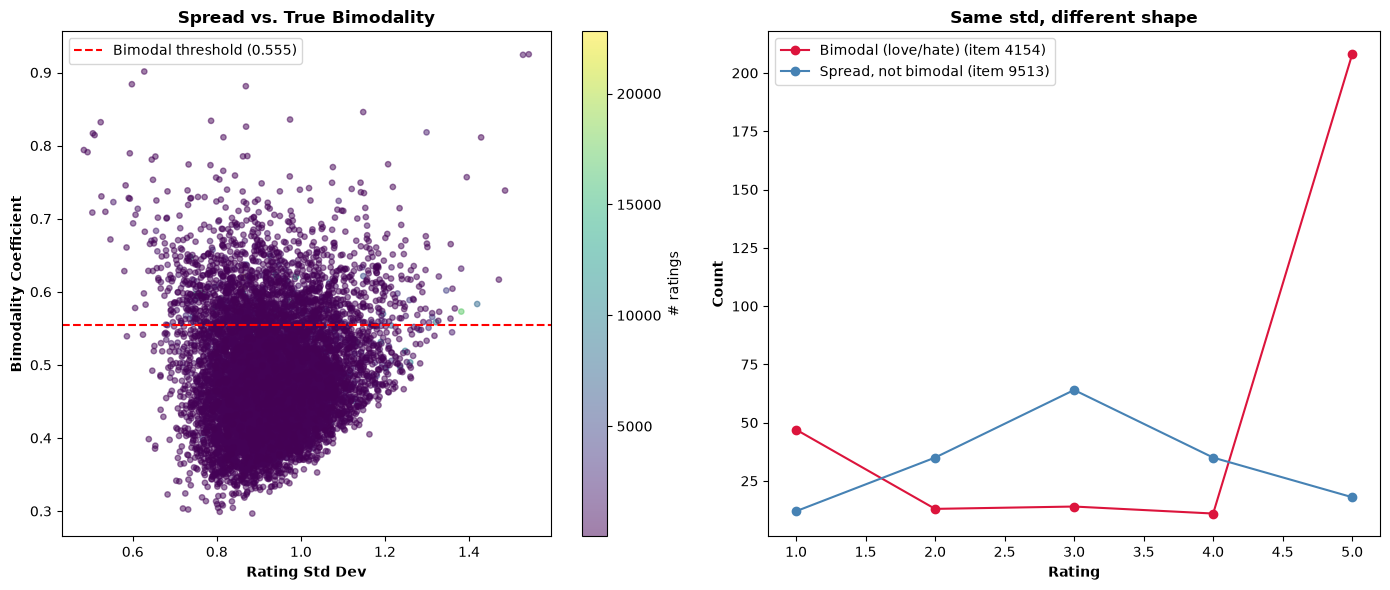

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sc = axes[0].scatter(item_stats["std"], item_stats["bimodality_coef"],
                      c=item_stats["count"], cmap="viridis", alpha=0.5, s=15)
axes[0].axhline(0.555, color="red", linestyle="--", label="Bimodal threshold (0.555)")
axes[0].set_xlabel("Rating Std Dev", fontweight="bold")
axes[0].set_ylabel("Bimodality Coefficient", fontweight="bold")
axes[0].set_title("Spread vs. True Bimodality", fontweight="bold")
axes[0].legend()
plt.colorbar(sc, ax=axes[0], label="# ratings")

# Pick one high-std/high-BC item and one high-std/low-BC item to contrast shapes
truly_polarized = item_stats.query("bimodality_coef > 0.555").nlargest(1, "std").index[0]
just_spread = item_stats.query("bimodality_coef < 0.4").nlargest(1, "std").index[0]

for item_id, label, color in [(truly_polarized, "Bimodal (love/hate)", "crimson"),
                                (just_spread, "Spread, not bimodal", "steelblue")]:
    counts = data.loc[data.item_id == item_id, "rating"].value_counts().reindex([1,2,3,4,5], fill_value=0)
    axes[1].plot([1,2,3,4,5], counts.values, marker="o", label=f"{label} (item {item_id})", color=color)

axes[1].set_xlabel("Rating", fontweight="bold")
axes[1].set_ylabel("Count", fontweight="bold")
axes[1].set_title("Same std, different shape", fontweight="bold")
axes[1].legend()
plt.tight_layout()
plt.show()

we measured the bimodal distribution of the ratings for polarity, a bimodal distribution has 2 peaks in our case a book with a lot of 1 and 5 ratings and less ratings in between.

We calculated the bimodal coefficient using:
BC = (skew² + 1) / (kurtosis + 3)
skew measures asymmetry of the distribution
kurtosis means how many ratings are in the peaks vs how many are in the tails. A true bimodal distribution has low kurtosis (it's "flat" in the middle because there's a valley, not a peak)






most polarizing item was "The Book of Mormon, Doctrine and Covenants, the Pearl of Great Price" published by church of latterday saints

In [ ]:
import lenskit



## 7. EDA Summary & Recommendations

### Key Findings
- **Dataset Size**: 5.98M ratings, 53K users, 10K books
- **Extreme Sparsity**: 98.88% of user-item matrix is empty
- **Strong Popularity Bias**: Top 1% of books get 17.1% of all ratings
- **Limited Group Overlap**: 60-94% of random groups have NO common rated books
- **Rating Bias**: Users vary widely in generosity (mean ratings: 1.0-5.0)
- **High-Quality Metadata**: 100% coverage for titles/authors, 100% for tags

### Additions we considered

-Cold-start analysis, for say books with less than 5 ratings
-Rating variability per book:Which books get polarized ratings (1/5) vs consensus (4)? Affects model reliability

-Clustering the content based on authors because author overlap ~80% of books

-Train/val/test split strategy: no time stamps we will use user based splitting

-Fallback frequency estimates: For each model: % of users/items covered, % requiring content-based fallback

-Top-k recommendation diversity: When group size=5, how much do top-k lists overlap?

### What are we going to do next?
1. Implement SVD baseline + Least Misery aggregation
2. Test item-kNN as optional comparison (smaller memory allocation)
3. Prepare tag TF-IDF + author clustering for cold-start fallback
4. Document train/val/test split; measure coverage and fallback rates
5. Skip user-kNN; too memory-intensive and overlap too sparse to be reliable
6. Implement the lenskit algorithm ALS-based biased matrix factorization:
    -biased mf predicts ratings explicitly, our data is explicit ratings
    -user ratings range from 1 to 5, biased mf models global,user and item bias before other factors so we will have reduced variance
    -we have 53k users and 10k books with about 5 million ratings with high sparsity. ALS based biased mf scales well to our dataset.
